**Personalized Treatment Recommendation using SARSA**

Final Q Table
[[4.30282989 0.34819588 7.13329417]
 [6.15896923 5.25595752 9.36235257]
 [7.16578014 6.89717255 8.50937865]
 [5.         6.37362495 3.99998837]
 [0.         0.         0.        ]]


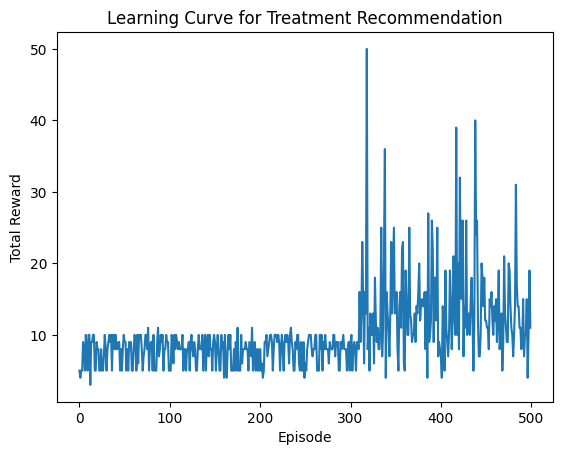

In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt

# -----------------------------
# Environment Setup
# -----------------------------

# Patient health states
# 0 = Critical
# 1 = Poor
# 2 = Moderate
# 3 = Good
# 4 = Recovered

num_states = 5

# Treatment options
# 0 = Medication A
# 1 = Medication B
# 2 = Therapy

num_actions = 3

# Initialize Q-table
Q = np.zeros((num_states, num_actions))

# -----------------------------
# Hyperparameters
# -----------------------------

alpha = 0.1        # Learning rate
gamma = 0.9        # Discount factor
epsilon = 0.2      # Exploration rate
episodes = 500

rewards_per_episode = []

# -----------------------------
# Patient Transition Function
# -----------------------------

def patient_response(state, action):

    # Simple simulated transition probabilities
    transition = {
        (0,0): (1, -2),   # Critical + Med A
        (0,1): (0, -3),
        (0,2): (1, -1),

        (1,0): (2, 1),
        (1,1): (1, -1),
        (1,2): (2, 2),

        (2,0): (3, 2),
        (2,1): (2, 0),
        (2,2): (3, 3),

        (3,0): (4, 5),
        (3,1): (3, 1),
        (3,2): (4, 4),

        (4,0): (4, 0),
        (4,1): (4, 0),
        (4,2): (4, 0)
    }

    next_state, reward = transition[(state,action)]
    return next_state, reward

# -----------------------------
# Epsilon-Greedy Policy
# -----------------------------

def choose_action(state):

    if random.uniform(0,1) < epsilon:
        return random.randint(0, num_actions-1)
    else:
        return np.argmax(Q[state])

# -----------------------------
# SARSA Training
# -----------------------------

for episode in range(episodes):

    state = random.randint(0,3)   # patient initial state
    action = choose_action(state)

    total_reward = 0

    while state != 4:   # until recovered

        next_state, reward = patient_response(state, action)
        next_action = choose_action(next_state)

        # SARSA Update Rule
        Q[state][action] = Q[state][action] + alpha * (
            reward + gamma * Q[next_state][next_action] - Q[state][action]
        )

        state = next_state
        action = next_action

        total_reward += reward

    rewards_per_episode.append(total_reward)

# -----------------------------
# Results
# -----------------------------

print("Final Q Table")
print(Q)

# Plot learning curve
plt.plot(rewards_per_episode)
plt.title("Learning Curve for Treatment Recommendation")
plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.show()